## EDA кредитного скоринга
Анализ данных для предсказания дефолта клиентов по кредитным картам.

In [19]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
%matplotlib inline

### Загрузка датасета

In [20]:
# Загрузка дата сета
df = pd.read_csv("../data/raw/UCI_Credit_Card.csv")
nRow, nCol = df.shape
print(f"В датасете {nRow} строк и {nCol} столбцов")

В датасете 30000 строк и 25 столбцов


Копируем датасет в defaulters для дальнейших вычислений.
Смотрим первые строки чтобы убедиться что данные прочитались верно.

In [21]:
defaulters = df.copy()
print(defaulters.shape)
defaulters.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [22]:
defaulters.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


Все столбцы имеют одинаковый count, значит пропусков нет.
Статус погашения идет в столбцах PAY_0, PAY_2 ... без PAY_1, поэтому переименуем PAY_0 в PAY_1 для удобства.

In [23]:
# PAY_0 переименуем в PAY_1 и default.payment.next.month в target
defaulters = defaulters.rename(
    columns={
        "PAY_0": "PAY_1",
        "default.payment.next.month": "target",
    }
)

Проверяем типы данных и пропуски. Все столбцы int64, хотя SEX, EDUCATION, MARRIAGE, PAY_* по сути категориальные.

In [24]:
# Проверка типов данных
defaulters.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         30000 non-null  int64  
 1   LIMIT_BAL  30000 non-null  float64
 2   SEX        30000 non-null  int64  
 3   EDUCATION  30000 non-null  int64  
 4   MARRIAGE   30000 non-null  int64  
 5   AGE        30000 non-null  int64  
 6   PAY_1      30000 non-null  int64  
 7   PAY_2      30000 non-null  int64  
 8   PAY_3      30000 non-null  int64  
 9   PAY_4      30000 non-null  int64  
 10  PAY_5      30000 non-null  int64  
 11  PAY_6      30000 non-null  int64  
 12  BILL_AMT1  30000 non-null  float64
 13  BILL_AMT2  30000 non-null  float64
 14  BILL_AMT3  30000 non-null  float64
 15  BILL_AMT4  30000 non-null  float64
 16  BILL_AMT5  30000 non-null  float64
 17  BILL_AMT6  30000 non-null  float64
 18  PAY_AMT1   30000 non-null  float64
 19  PAY_AMT2   30000 non-null  float64
 20  PAY_AMT3   30000 

In [25]:
# Проверка пропусков для сурности
print("=" * 60)
print(defaulters.isnull().sum())
print("=" * 60)
print("Дубликатов:", defaulters.duplicated().sum())
print("=" * 60)

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
target       0
dtype: int64
Дубликатов: 0


Пропусков нет, импутация не нужна. Переходим к визуализации.

Сначала выбираем признаки которые скорее всего больше всего связаны с таргетом.
Нам нужно предсказать будет ли клиент дефолт по платежу в следующем месяце.
Это зависит в основном от истории погашений, лимита баланса, возраста, образования и семейного положения.

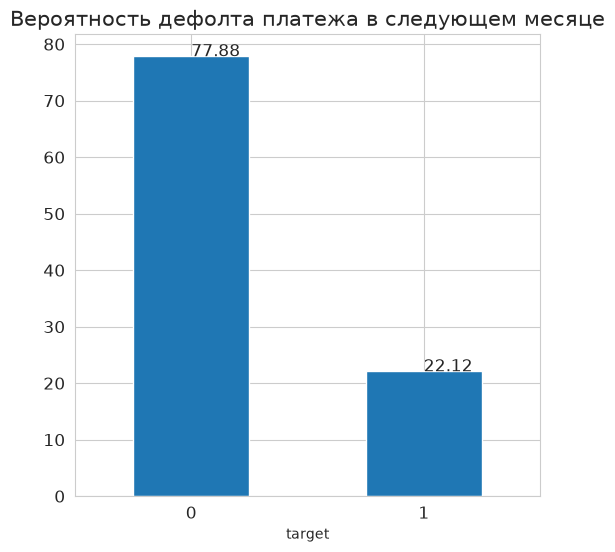

In [26]:
def_cnt = defaulters.target.value_counts(normalize=True) * 100
def_cnt.plot.bar(figsize=(6, 6))
plt.xticks(fontsize=12, rotation=0)
plt.yticks(fontsize=12)
plt.title("Вероятность дефолта платежа в следующем месяце", fontsize=15)
for x, y in zip([0, 1], def_cnt):
    plt.text(x, y, round(y, 2), fontsize=12)
plt.show()

Видим что 77% клиентов не ожидают дефолт, а 23% ожидают дефолт по платежу.

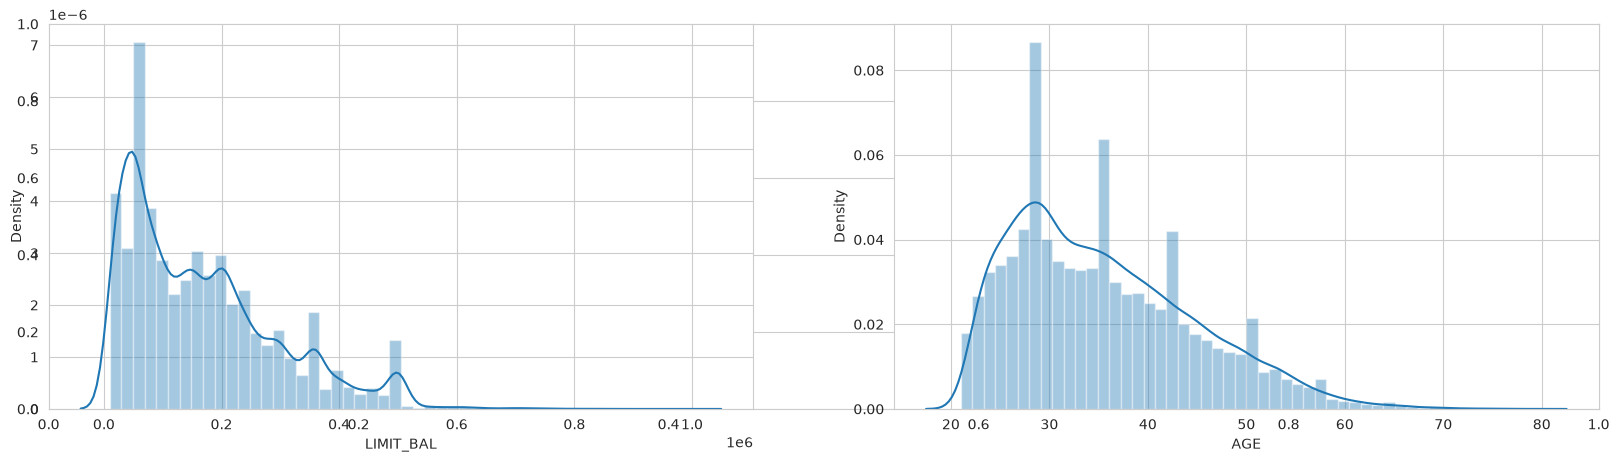

In [27]:
plt.subplots(figsize=(20, 5))
plt.subplot(121)
sns.distplot(defaulters.LIMIT_BAL)

plt.subplot(122)
sns.distplot(defaulters.AGE)

plt.show()

Распределения лимита баланса и возраста скошены.
Больше всего клиентов с лимитом от 0 до 200000 и в возрасте от 20 до 40 лет.

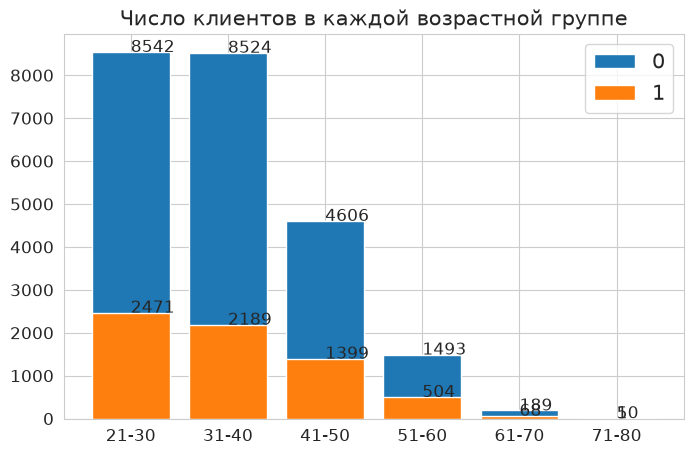

In [28]:
bins = [20, 30, 40, 50, 60, 70, 80]
names = ["21-30", "31-40", "41-50", "51-60", "61-70", "71-80"]
defaulters["AGE_BIN"] = pd.cut(x=defaulters.AGE, bins=bins, labels=names, right=True)

age_0 = defaulters.AGE_BIN[defaulters["target"] == 0].value_counts()
age_1 = defaulters.AGE_BIN[defaulters["target"] == 1].value_counts()

plt.subplots(figsize=(8, 5))
plt.bar(age_0.index, age_0.values, label="0")
plt.bar(age_1.index, age_1.values, label="1")
for x, y in zip(names, age_0):
    plt.text(x, y, y, fontsize=12)
for x, y in zip(names, age_1):
    plt.text(x, y, y, fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.title("Число клиентов в каждой возрастной группе", fontsize=15)
plt.legend(loc="upper right", fontsize=15)
plt.show()

Больше всего клиентов в группе 21-30, затем 31-40. С ростом возраста число дефолтов падает,
значит возраст важный признак для предсказания дефолта.

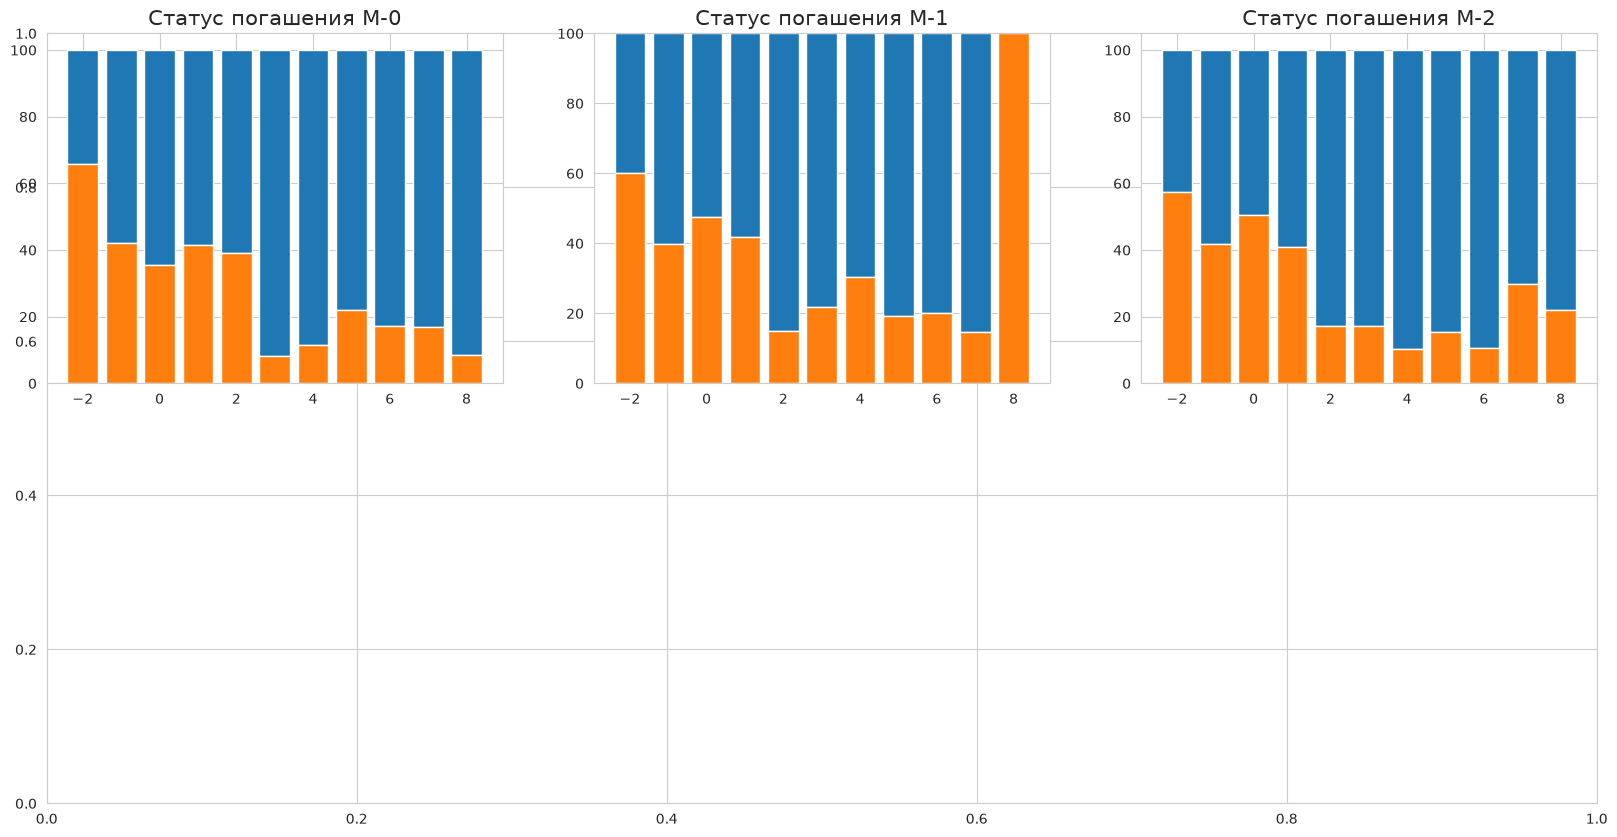

In [29]:
plt.subplots(figsize=(20, 10))

ind = sorted(defaulters.PAY_1.unique())
pay_0 = defaulters.PAY_1[defaulters["target"] == 0].value_counts(normalize=True)
pay_1 = defaulters.PAY_1[defaulters["target"] == 1].value_counts(normalize=True)
total = pay_0.values + pay_1.values
pay_0_prop = np.true_divide(pay_0, total) * 100
pay_1_prop = np.true_divide(pay_1, total) * 100
plt.subplot(231)
plt.bar(ind, pay_1_prop, bottom=pay_0_prop, label="1")
plt.bar(ind, pay_0_prop, label="0")
plt.title("Статус погашения M-0", fontsize=15)

ind = sorted(defaulters.PAY_2.unique())
pay_0 = defaulters.PAY_2[defaulters["target"] == 0].value_counts(normalize=True)
pay_1 = defaulters.PAY_2[defaulters["target"] == 1].value_counts(normalize=True)
for i in pay_0.index:
    if i not in pay_1.index:
        pay_1[i] = 0
total = pay_0.values + pay_1.values
pay_0_prop = np.true_divide(pay_0, total) * 100
pay_1_prop = np.true_divide(pay_1, total) * 100
plt.subplot(232)
plt.bar(ind, pay_1_prop, bottom=pay_0_prop, label="1")
plt.bar(ind, pay_0_prop, label="0")
plt.title("Статус погашения M-1", fontsize=15)

ind = sorted(defaulters.PAY_3.unique())
pay_0 = defaulters.PAY_3[defaulters["target"] == 0].value_counts(normalize=True)
pay_1 = defaulters.PAY_3[defaulters["target"] == 1].value_counts(normalize=True)
for i in pay_0.index:
    if i not in pay_1.index:
        pay_1[i] = 0
total = pay_0.values + pay_1.values
pay_0_prop = np.true_divide(pay_0, total) * 100
pay_1_prop = np.true_divide(pay_1, total) * 100
plt.subplot(233)
plt.bar(ind, pay_1_prop, bottom=pay_0_prop, label="1")
plt.bar(ind, pay_0_prop, label="0")
plt.title("Статус погашения M-2", fontsize=15)

plt.show()

График показывает долю клиентов с дефолтом в зависимости от истории погашений.
Чем раньше сделан платеж тем меньше шанс дефолта.

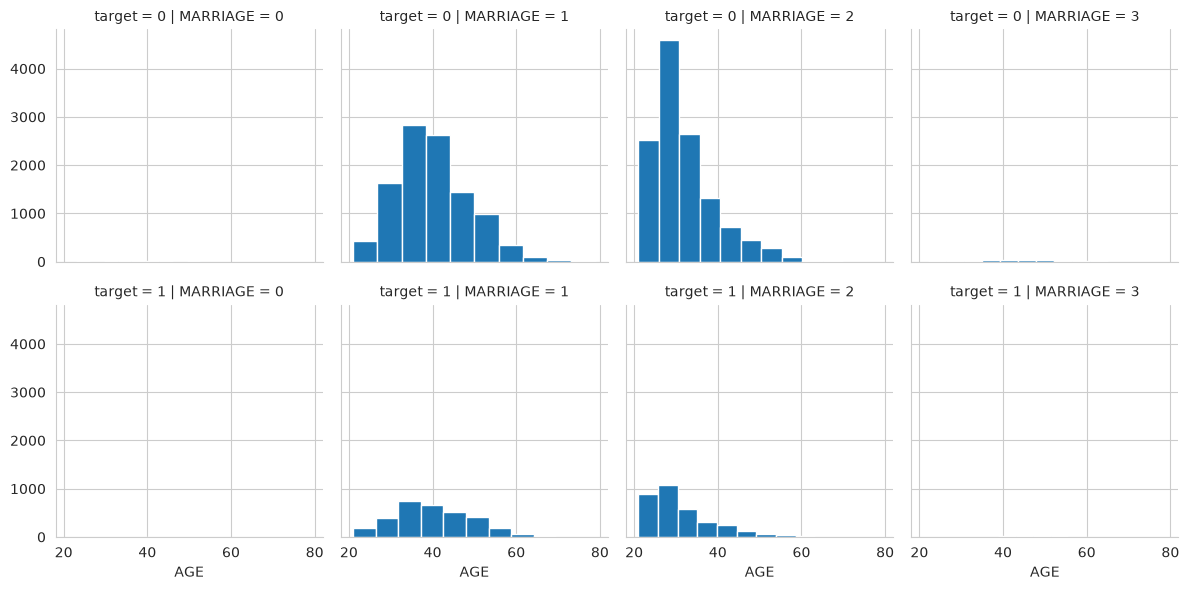

In [30]:
g = sns.FacetGrid(defaulters, row="target", col="MARRIAGE")
g = g.map(plt.hist, "AGE")
plt.show()

Женатые клиенты 30-50 лет и неженатые 20-30 чаще уходят в дефолт,
причем у неженатых вероятность выше. Значит MARRIAGE полезный признак.

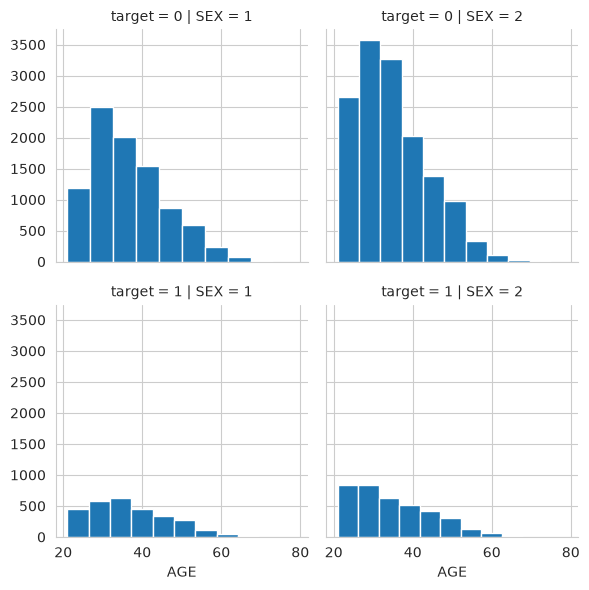

In [31]:
g = sns.FacetGrid(defaulters, row="target", col="SEX")
g = g.map(plt.hist, "AGE")
plt.show()

Женщины 20-30 лет чаще уходят в дефолт чем мужчины во всех возрастах.
Поэтому столбец SEX оставляем для предсказания.

Теперь проверяем влияют ли суммы счетов за прошлые шесть месяцев на дефолт.

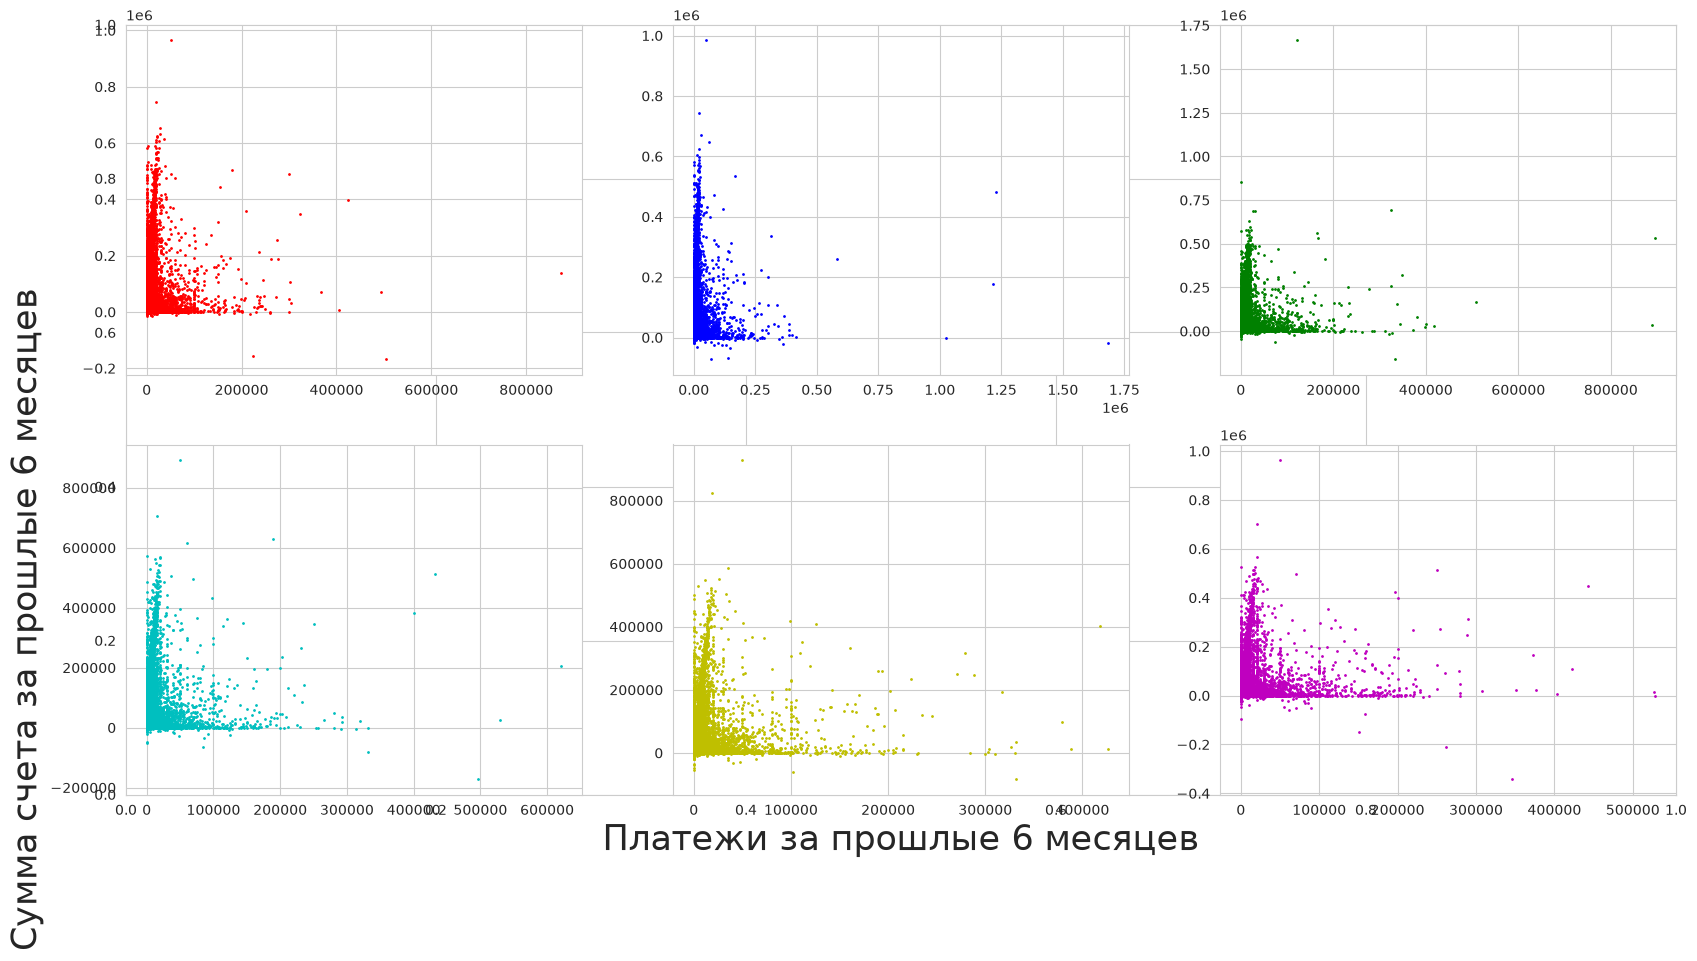

In [32]:
plt.subplots(figsize=(20, 10))

plt.subplot(231)
plt.scatter(x=defaulters.PAY_AMT1, y=defaulters.BILL_AMT1, c="r", s=1)

plt.subplot(232)
plt.scatter(x=defaulters.PAY_AMT2, y=defaulters.BILL_AMT2, c="b", s=1)

plt.subplot(233)
plt.scatter(x=defaulters.PAY_AMT3, y=defaulters.BILL_AMT3, c="g", s=1)

plt.subplot(234)
plt.scatter(x=defaulters.PAY_AMT4, y=defaulters.BILL_AMT4, c="c", s=1)
plt.ylabel("Сумма счета за прошлые 6 месяцев", fontsize=25)

plt.subplot(235)
plt.scatter(x=defaulters.PAY_AMT5, y=defaulters.BILL_AMT5, c="y", s=1)
plt.xlabel("Платежи за прошлые 6 месяцев", fontsize=25)

plt.subplot(236)
plt.scatter(x=defaulters.PAY_AMT6, y=defaulters.BILL_AMT6, c="m", s=1)

plt.show()

Видно что много клиентов с большой суммой счета но очень маленьким платежем,
точки плотно собраны вдоль оси Y у нуля по оси X.

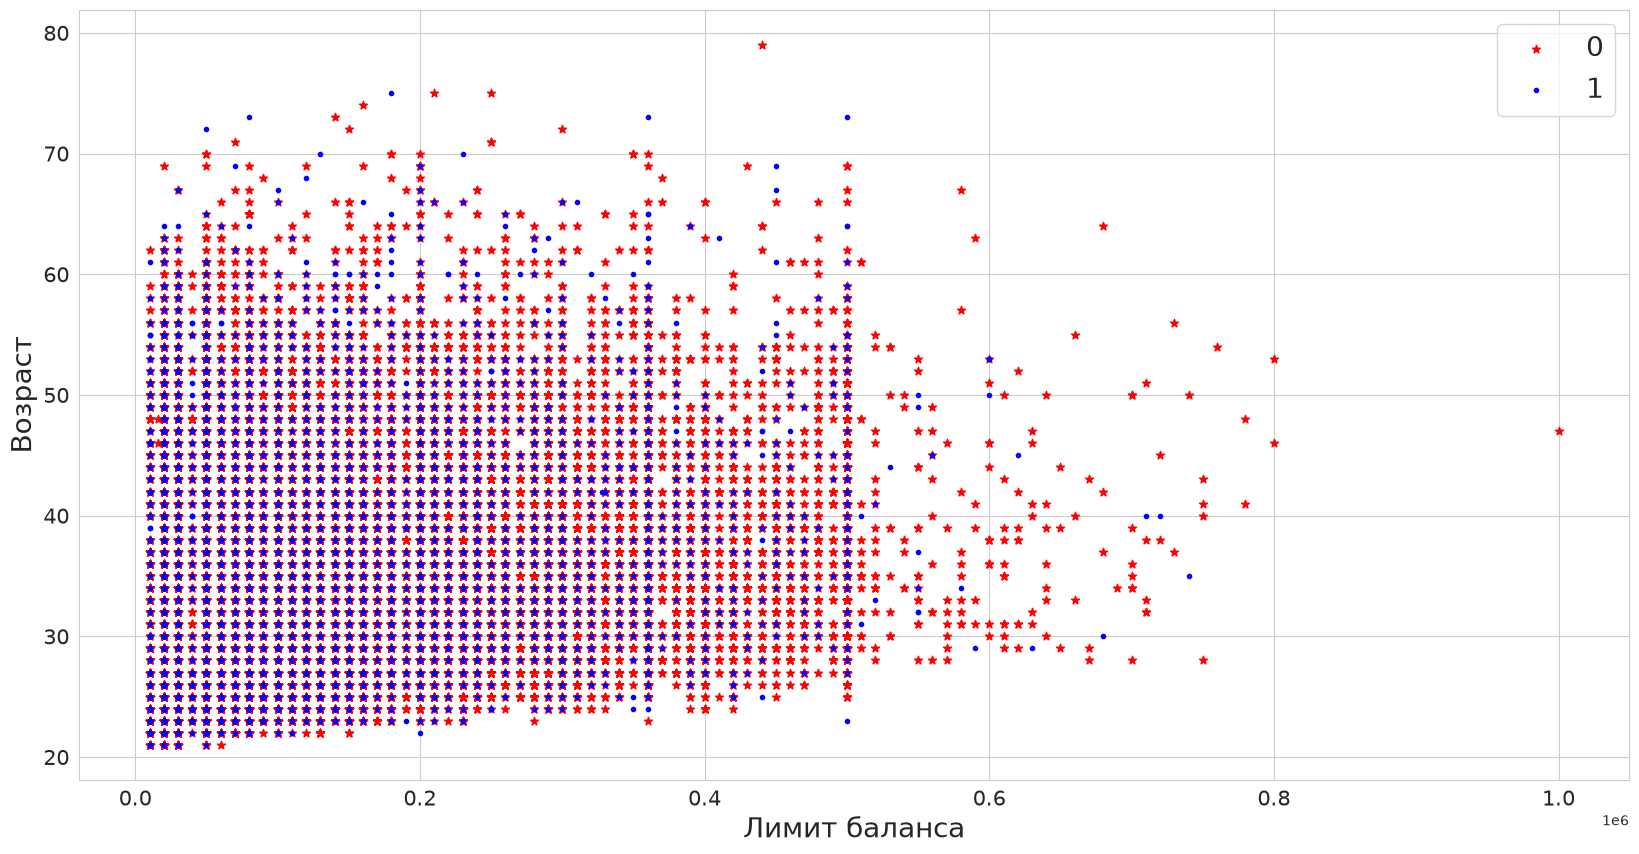

In [33]:
y1 = defaulters.AGE[defaulters["target"] == 0]
y2 = defaulters.AGE[defaulters["target"] == 1]
x1 = defaulters.LIMIT_BAL[defaulters["target"] == 0]
x2 = defaulters.LIMIT_BAL[defaulters["target"] == 1]

fig, ax = plt.subplots(figsize=(20, 10))
plt.scatter(x1, y1, color="r", marker="*", label="0")
plt.scatter(x2, y2, color="b", marker=".", label="1")
plt.xlabel("Лимит баланса", fontsize=20)
plt.ylabel("Возраст", fontsize=20)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.legend(loc="upper right", fontsize=20)
plt.show()

График возраста против лимита баланса не дает точной информации,
клиенты всех возрастов и лимитов перемешаны.

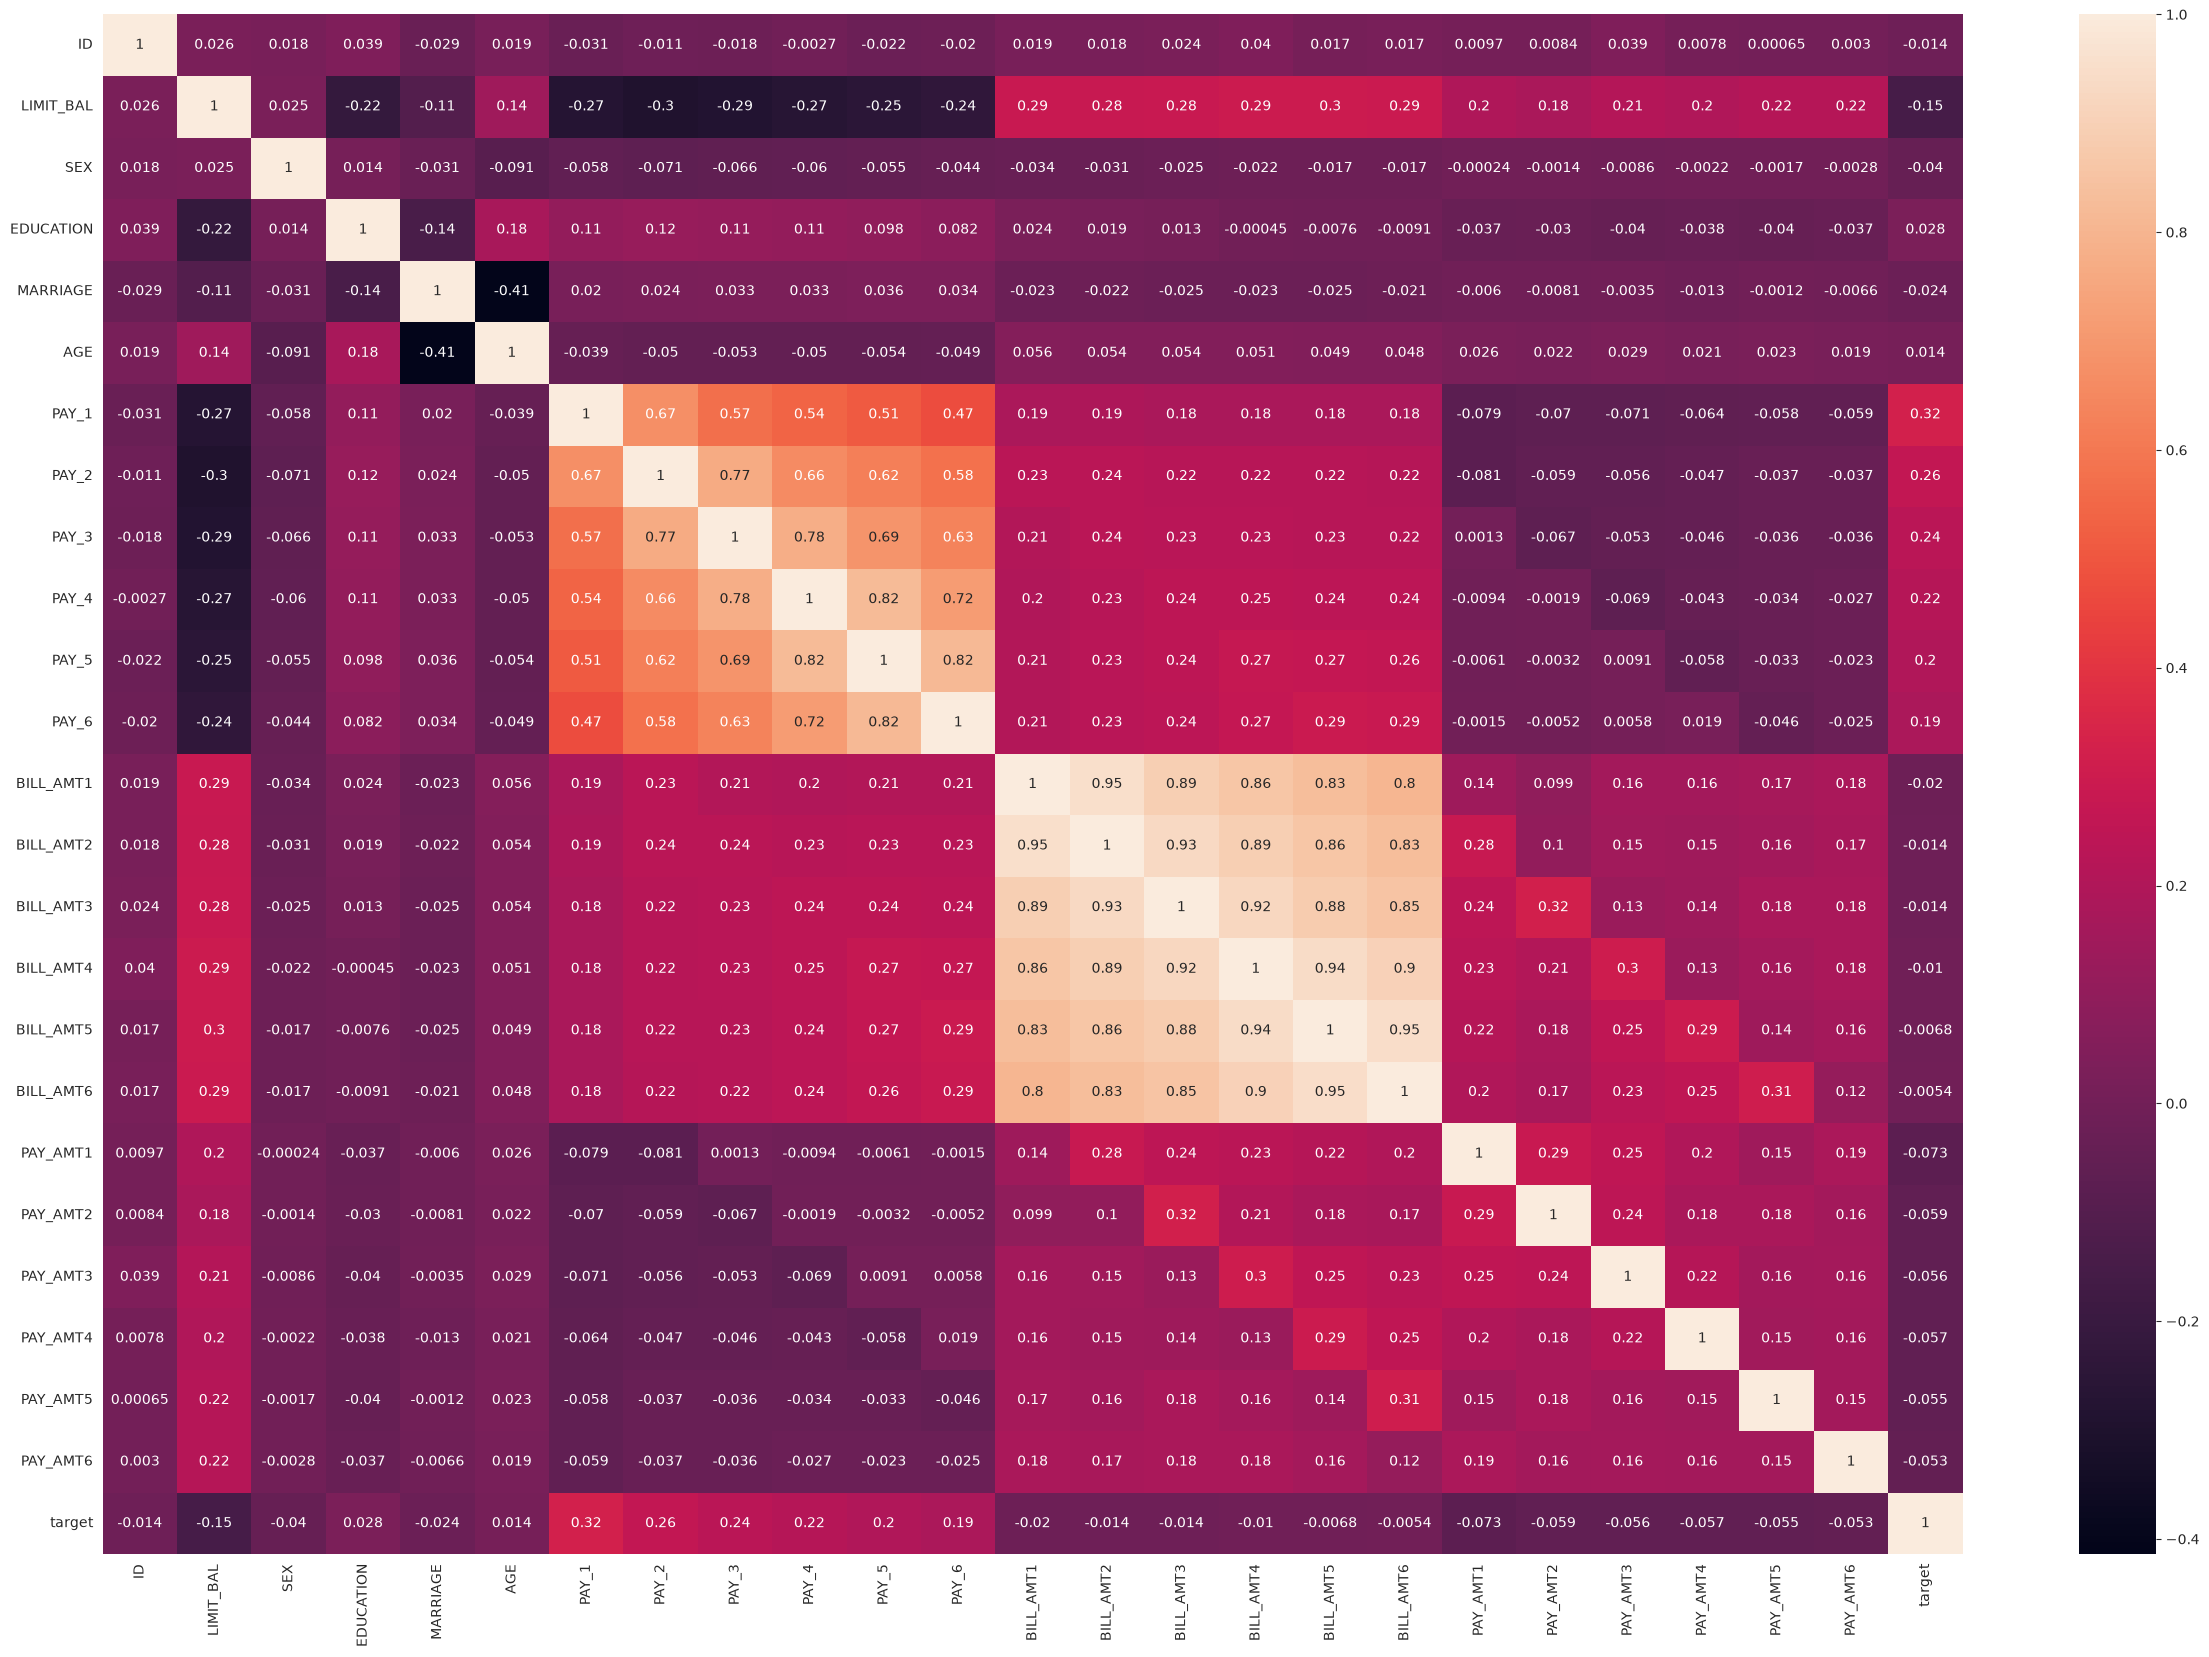

In [34]:
plt.subplots(figsize=(30, 20))
sns.heatmap(defaulters.corr(numeric_only=True), annot=True)
plt.show()

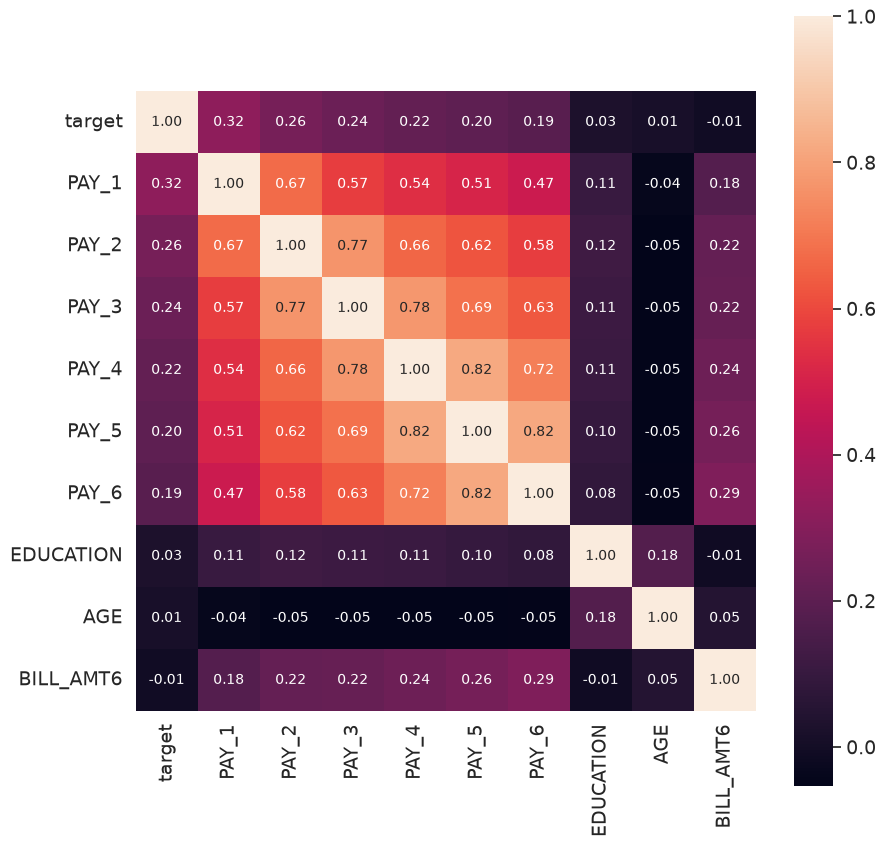

In [35]:
# Корреляционная матрица топ признаков с target
k = 10  # число признаков для heatmap
corrmat = defaulters.corr(numeric_only=True)
cols = corrmat.nlargest(k, "target")["target"].index
cm = np.corrcoef(defaulters[cols].values.T)
sns.set(font_scale=1.25)
plt.subplots(figsize=(10, 10))
sns.heatmap(
    cm,
    cbar=True,
    annot=True,
    square=True,
    fmt=".2f",
    annot_kws={"size": 10},
    yticklabels=cols.values,
    xticklabels=cols.values,
)
plt.show()

Дефолт в следующем месяце зависит от статуса погашения за прошлые шесть месяцев.
Но между признаками PAY_* есть мультиколлинеарность, что стоит учесть при обучении модели.

## Итоговый вывод

- **Данные:** 30000 строк, 25 столбцов, пропусков и дубликатов нет, импутация не требуется.
- **Целевая переменная несбалансирована:** ~78% клиентов без дефолта и ~22% с дефолтом — это нужно учитывать при обучении (взвешивание классов / метрики ROC-AUC, F1 вместо accuracy).
- **Наиболее информативные признаки** — история статусов погашения `PAY_1`–`PAY_6`: чем хуже статус погашения, тем выше вероятность дефолта. Между этими признаками есть заметная мультиколлинеарность.
- **Демографические признаки** (`AGE`, `SEX`, `MARRIAGE`, `EDUCATION`) дают дополнительный, но более слабый сигнал: с ростом возраста доля дефолтов падает, у молодых и неженатых клиентов риск выше.
- **Суммы счетов и платежей** (`BILL_AMT*`, `PAY_AMT*`) слабо коррелируют с таргетом напрямую, но полезны для инженерии признаков (например, доля погашения счёта).

